## EDA

Six 3-flute ball-nose carbide cutters (c1–c6)

In [ ]:
from enum import StrEnum
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("../data")


class Cutter(StrEnum):
    C1 = "c1"
    C2 = "c2"
    C3 = "c3"
    C4 = "c4"
    C5 = "c5"
    C6 = "c6"


class Channel(StrEnum):
    FORCE_X = "force_x"
    FORCE_Y = "force_y"
    FORCE_Z = "force_z"
    VIB_X = "vib_x"
    VIB_Y = "vib_y"
    VIB_Z = "vib_z"
    AE_RMS = "ae_rms"


class Flute(StrEnum):
    FLUTE_1 = "flute_1"
    FLUTE_2 = "flute_2"
    FLUTE_3 = "flute_3"


train_cutters = [Cutter.C1, Cutter.C4, Cutter.C6]

FS = 50_000  # Hz
SPINDLE_HZ = 10_400 / 60  # ~173 Hz
TOOTH_HZ = 3 * SPINDLE_HZ  # ~520 Hz, tooth passing frequency
WEAR_LIMIT = 165  # 10^-3 mm

In [12]:
# plot settings

COLORS = dict(zip(Cutters, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"], strict=True))
FLUTE_COLORS = dict(zip(Flutes, ["#2a78d6", "#eb6834", "#1baf7a"], strict=True))

plt.rcParams.update({
    "figure.figsize": (12, 4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 1.5,
})

In [9]:
def load_wear(cutter: Cutters) -> pd.DataFrame:
    wear = pd.read_csv(DATA_DIR / cutter / f"{cutter}_wear.csv")
    wear["wear"] = wear[list(Flutes)].max(axis=1)  # worst flute drives tool life
    return wear


def load_cut(cutter: Cutters, cut: int) -> pd.DataFrame:
    path = DATA_DIR / cutter / cutter / f"c_{cutter[1]}_{cut:03d}.csv"
    return pd.read_csv(path, header=None, names=list(Channels), engine="pyarrow", dtype="float32")


def n_cuts(cutter: Cutters) -> int:
    return len(list((DATA_DIR / cutter / cutter).glob("*.csv")))


wear = {cutter: load_wear(cutter) for cutter in train_cutters}
pd.DataFrame({cutter: n_cuts(cutter) for cutter in Cutters}, index=["cuts"])

,c1,c2,c3,c4,c5,c6
cuts,315,315,315,315,315,315


### Wear labels

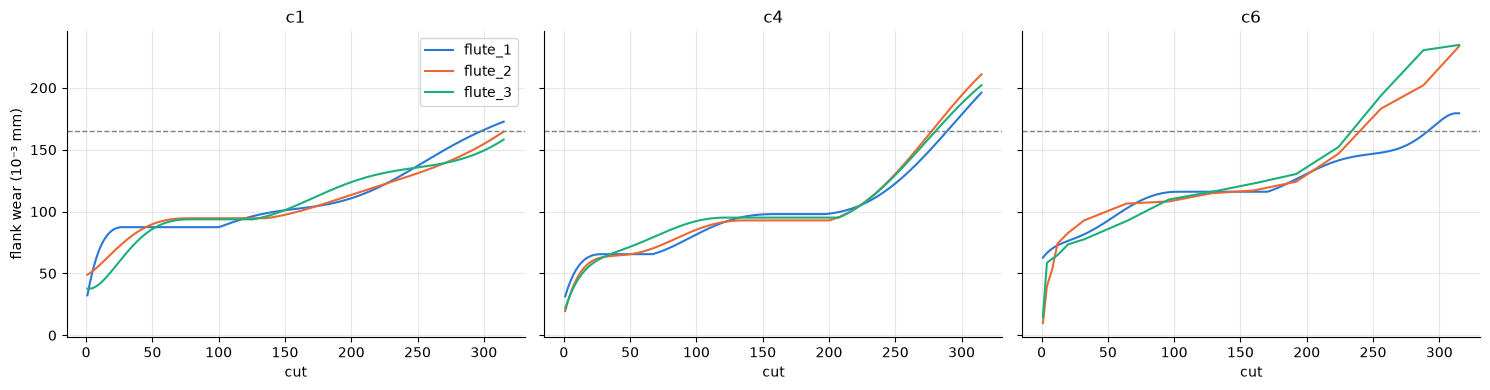

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, cutter in zip(axes, train_cutters, strict=False):
    for flute in Flutes:
        ax.plot(wear[cutter]["cut"], wear[cutter][flute], color=FLUTE_COLORS[flute], label=flute)
    ax.axhline(WEAR_LIMIT, color="gray", ls="--", lw=1)
    ax.set(title=cutter, xlabel="cut")
axes[0].set_ylabel("flank wear (10⁻³ mm)")
axes[0].legend()
plt.tight_layout()

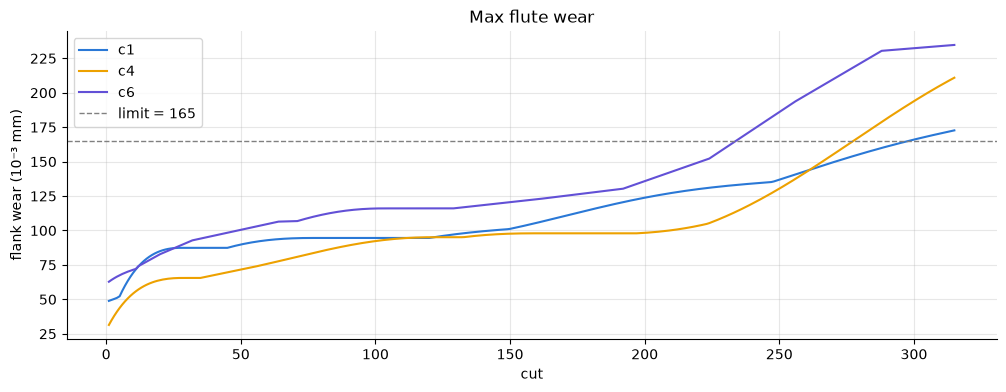

In [13]:
fig, ax = plt.subplots()
for cutter in train_cutters:
    ax.plot(wear[cutter]["cut"], wear[cutter]["wear"], color=COLORS[cutter], label=cutter)
ax.axhline(WEAR_LIMIT, color="gray", ls="--", lw=1, label=f"limit = {WEAR_LIMIT}")
ax.set(title="Max flute wear", xlabel="cut", ylabel="flank wear (10⁻³ mm)")
ax.legend()

In [14]:
pd.DataFrame({
    c: {
        "initial": w["wear"].iloc[0],
        "final": w["wear"].iloc[-1],
        "mean_rate_per_cut": w["wear"].diff().mean(),
        "decreasing_steps": int((w["wear"].diff() < 0).sum()),
        "cut_at_limit": int(w.loc[w["wear"] >= WEAR_LIMIT, "cut"].iloc[0]),
    }
    for c, w in wear.items()
}).round(2)

,c1,c4,c6
initial,48.89,31.42,62.79
final,172.69,210.92,234.72
mean_rate_per_cut,0.39,0.57,0.55
decreasing_steps,0.00,0.00,0.00
cut_at_limit,298.00,278.00,234.00


Wear follows the classic three phases: fast break-in, steady linear wear, accelerated wear near end of life.

### Raw signals: fresh vs worn (c1)

In [15]:
fresh, worn = load_cut(Cutters.C1, 1), load_cut(Cutters.C1, 315)
fresh.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
force_x,127399.0,0.401,0.842,-2.501,-0.198,0.377,0.984,3.744
force_y,127399.0,0.629,1.636,-12.051,-0.342,0.641,1.635,10.724
force_z,127399.0,0.705,1.127,-3.243,-0.067,0.708,1.483,4.560
vib_x,127399.0,0.009,0.076,-0.316,-0.041,0.009,0.060,0.330
vib_y,127399.0,0.014,0.076,-0.317,-0.037,0.014,0.064,0.347
vib_z,127399.0,0.018,0.077,-0.315,-0.032,0.018,0.069,0.354
ae_rms,127399.0,-0.000,0.002,-0.005,-0.002,0.000,0.001,0.010


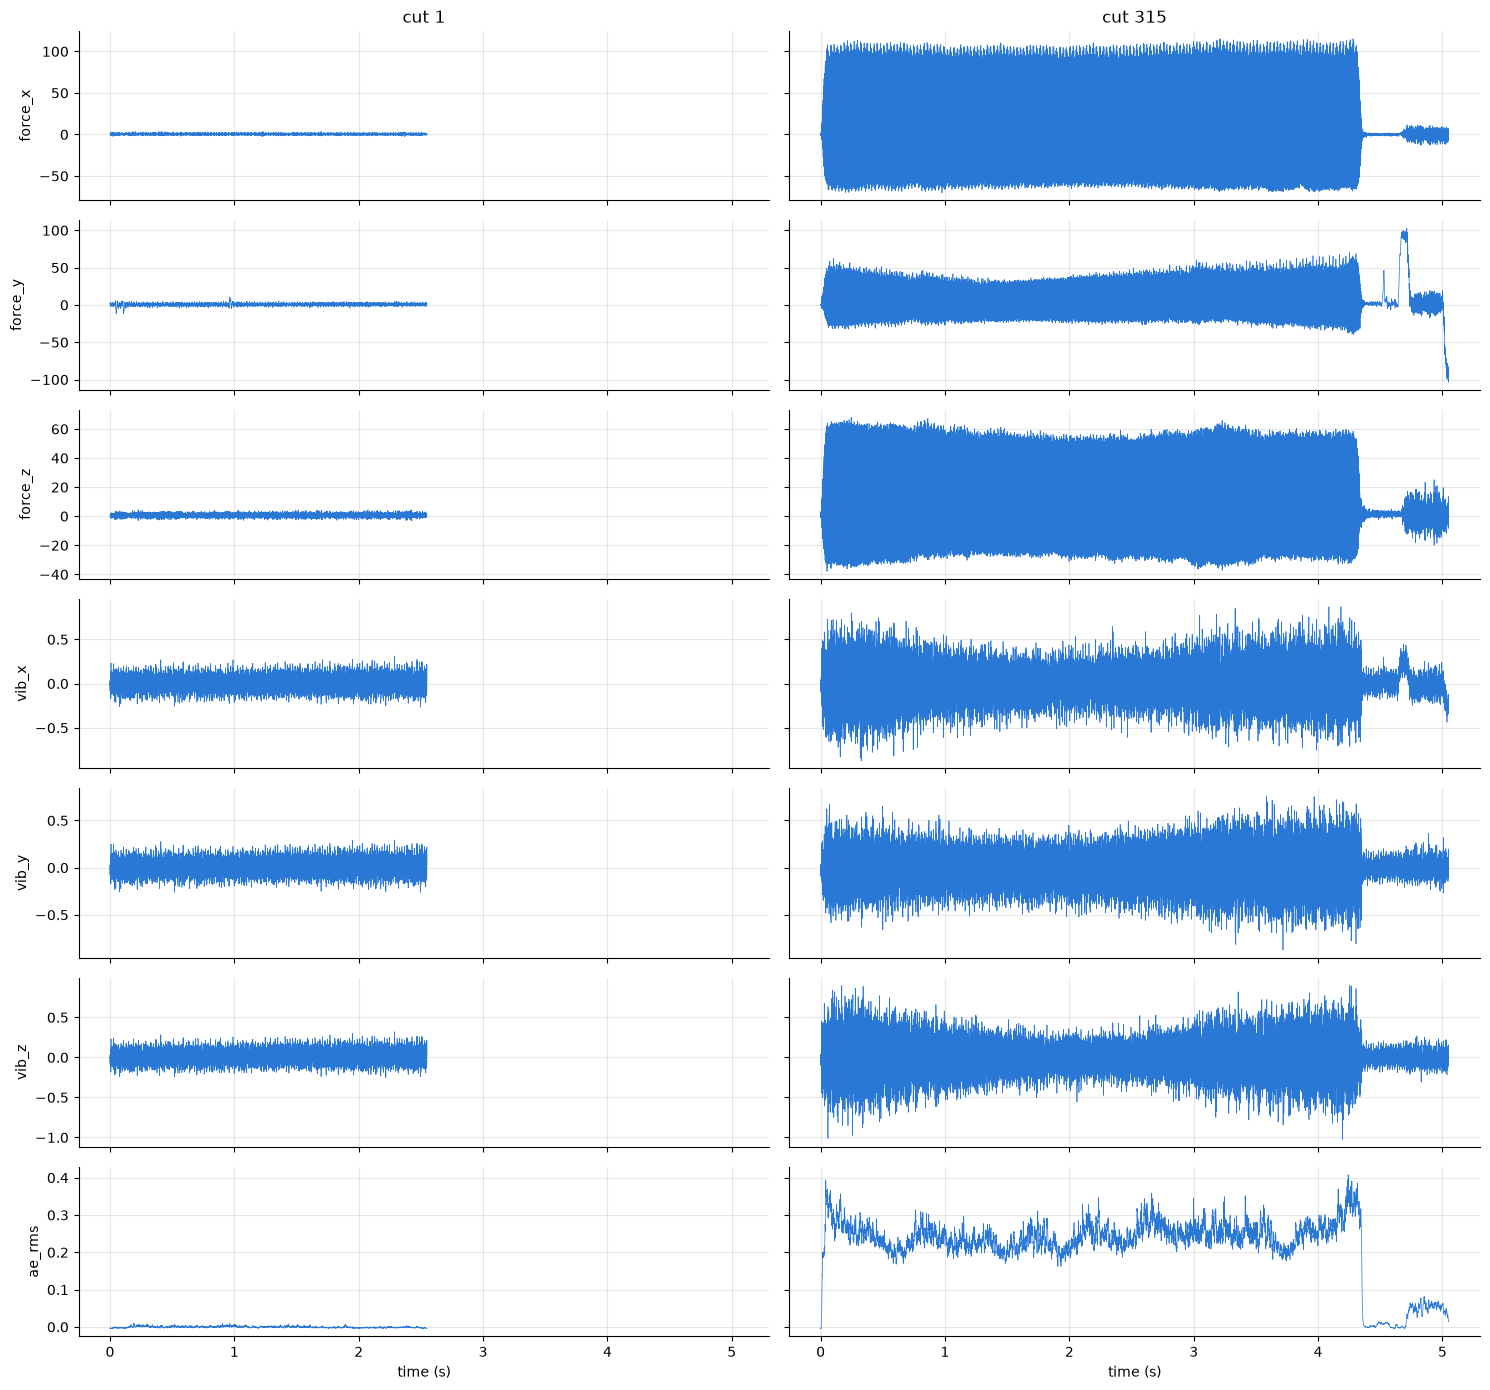

In [16]:
fig, axes = plt.subplots(len(Channels), 2, figsize=(15, 14), sharex=True, sharey="row")
for col, (name, df) in enumerate([("cut 1", fresh), ("cut 315", worn)]):
    t = np.arange(len(df)) / FS
    for row, channel in enumerate(Channels):
        axes[row, col].plot(t[::10], df[channel].values[::10], lw=0.5, color="#2a78d6")
        axes[row, 0].set_ylabel(channel)
    axes[0, col].set_title(name)
    axes[-1, col].set_xlabel("time (s)")
plt.tight_layout()

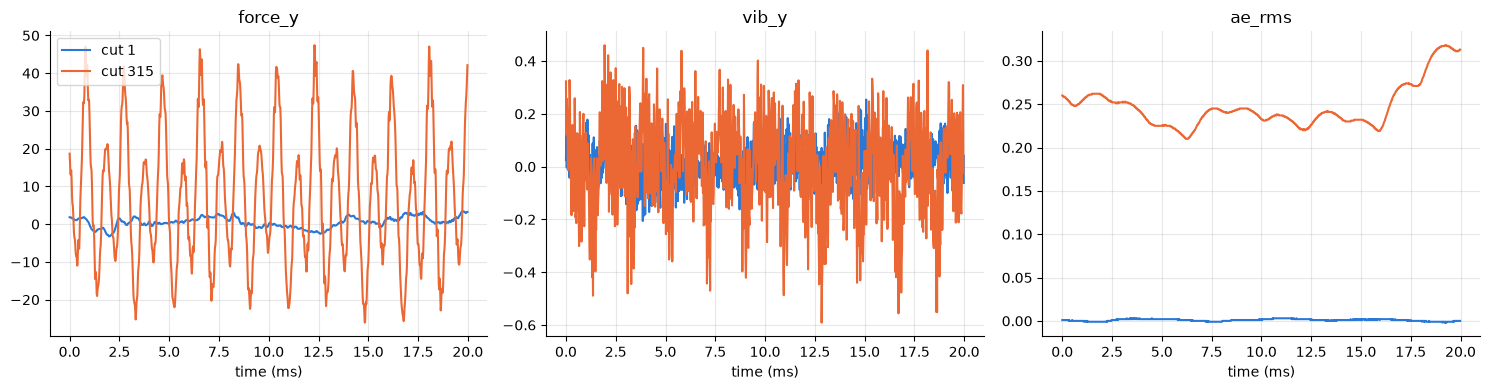

In [17]:
def window(df: pd.DataFrame, ms: float = 20) -> pd.DataFrame:
    start, n = len(df) // 2, int(FS * ms / 1000)
    return df.iloc[start : start + n].reset_index(drop=True)


fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, channel in zip(axes, [Channels.FORCE_Y, Channels.VIB_Y, Channels.AE_RMS], strict=False):
    for name, df, color in [("cut 1", fresh, "#2a78d6"), ("cut 315", worn, "#eb6834")]:
        w = window(df)
        ax.plot(w.index / FS * 1000, w[channel], color=color, label=name)
    ax.set(title=channel, xlabel="time (ms)")
axes[0].legend()
plt.tight_layout()

### RUL target

RUL = cuts remaining until max flute wear reaches `WEAR_LIMIT`, clipped at 0.

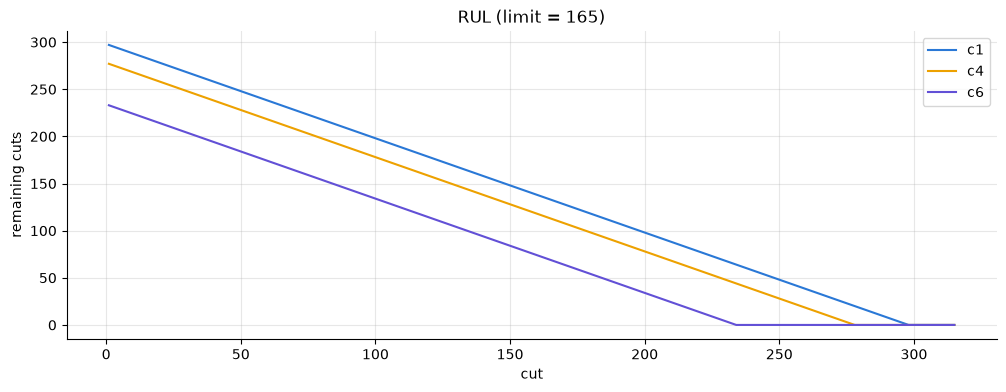

In [27]:
def rul(w: pd.DataFrame, limit: float = WEAR_LIMIT) -> pd.Series:
    eol = w.loc[w["wear"] >= limit, "cut"].iloc[0]
    return (eol - w["cut"]).clip(lower=0)


fig, ax = plt.subplots()
for cutter, w in wear.items():
    ax.plot(w["cut"], rul(w), color=COLORS[cutter], label=cutter)
ax.set(title=f"RUL (limit = {WEAR_LIMIT})", xlabel="cut", ylabel="remaining cuts")
ax.legend();